# Project 2, Moira's Dream Car

Working notebook. Reusable code lives in `src/`, and `make` runs the whole
pipeline. Every step here loads what is already in `output/` instead of
retraining it.

In [1]:
import os
import sys
from tqdm import tqdm
sys.path.insert(0, 'src')

import torch
import warnings
from matplotlib import pyplot as plt
from scipy.stats import spearmanr

from constants import *
from data import load_data, build_ratings, split_indices, make_loaders, denorm
from eda import correlation_matrix, top_decile, overlap_lift
from viz import show, show_tensor, rating_histograms
from regressor import make_regressor, train_regressor, constant_baseline, predict, evaluate
from model_fm import SinusoidalEmbedding, TimeMLP, ConEmbedding, ResBlock, AttenBlock, UNet

warnings.filterwarnings("ignore")
print(device)

/fp/homes01/u01/ec-armans/.venvImg/lib/python3.11/site-packages/quix/data/dataset.py:56: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


cuda


## Data

In [2]:
data = load_data()
ratings = build_ratings(data)

img, scores = data[42]
print(len(data), img.shape, scores.flatten())

6000 torch.Size([3, 96, 128]) tensor([6, 1, 5, 9, 3, 2])


## 1. Preference structure

The raters differ sharply in generosity. Moira sits at 1 to 2 and rarely goes
above 7, Ferdinando peaks at 9. Different marginals alone do not imply
disagreement, so the ranking correlation is what settles it.

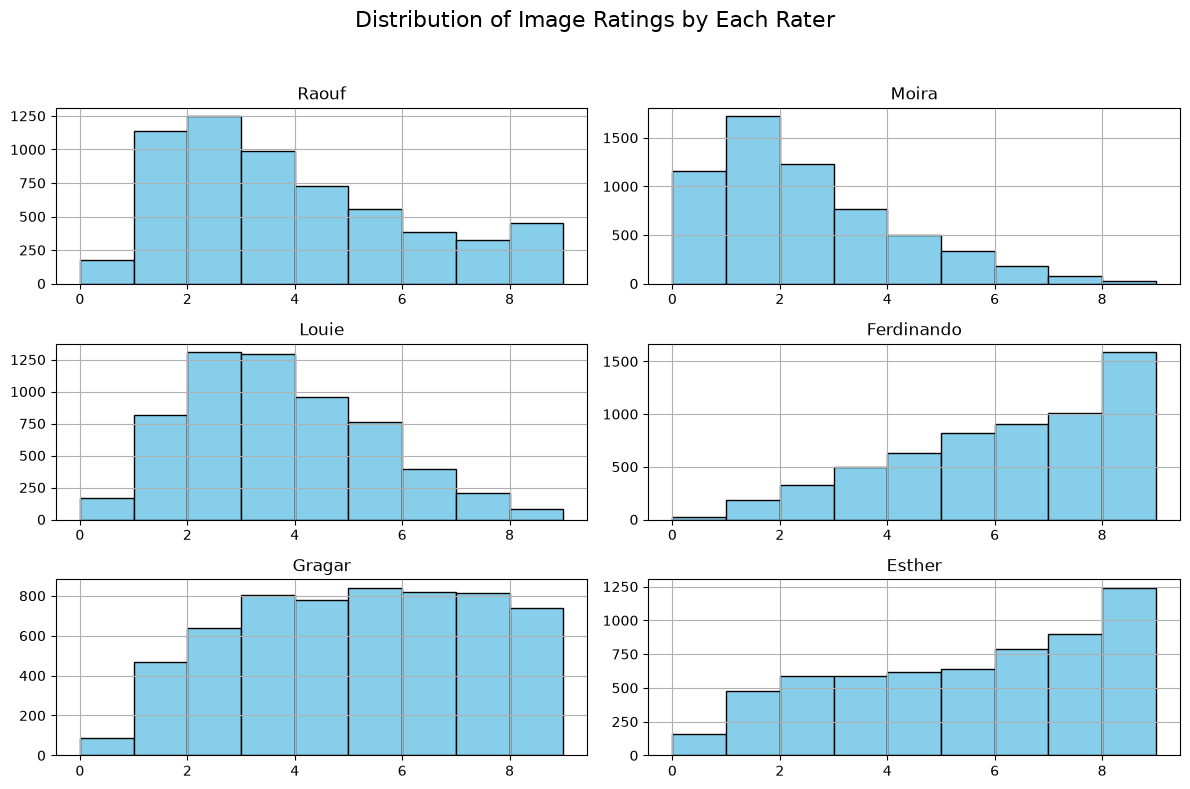

In [3]:
rating_histograms(ratings)
plt.show()

In [4]:
correlation_matrix(ratings).round(3)

,Raouf,Moira,Louie,Ferdinando,Gragar,Esther
Raouf,1.000,0.052,-0.111,-0.181,0.007,-0.435
Moira,0.052,1.000,-0.175,-0.271,0.121,0.227
Louie,-0.111,-0.175,1.000,0.365,-0.312,0.194
Ferdinando,-0.181,-0.271,0.365,1.000,-0.359,-0.077
Gragar,0.007,0.121,-0.312,-0.359,1.000,-0.059
Esther,-0.435,0.227,0.194,-0.077,-0.059,1.000


In [5]:
spearmanr(ratings['Moira'], ratings['Ferdinando'])

SignificanceResult(statistic=np.float64(-0.2710463185016363), pvalue=np.float64(1.5705000894171188e-101))

Their top deciles overlap three times less than chance, so the region that
satisfies both is thin: 55 cars out of 6000.

In [6]:
ov = overlap_lift(ratings, 'Moira', 'Ferdinando')
print({k: v for k, v in ov.items() if k != 'indices'})

shared_liked_cars = ov['indices']
moira_top = top_decile(ratings, 'Moira')
ferdinando_top = top_decile(ratings, 'Ferdinando')

{'n_a': 627, 'n_b': 1590, 'shared': 55, 'expected': 166.155, 'lift': 0.3310162197947699}


The conflict axis is body type, with colour following from it. Moira likes
sports cars in saturated colours, Ferdinando likes everyday vehicles in white
and silver. The shared set is his taste that she tolerates: almost every pair
reads M5 F9.

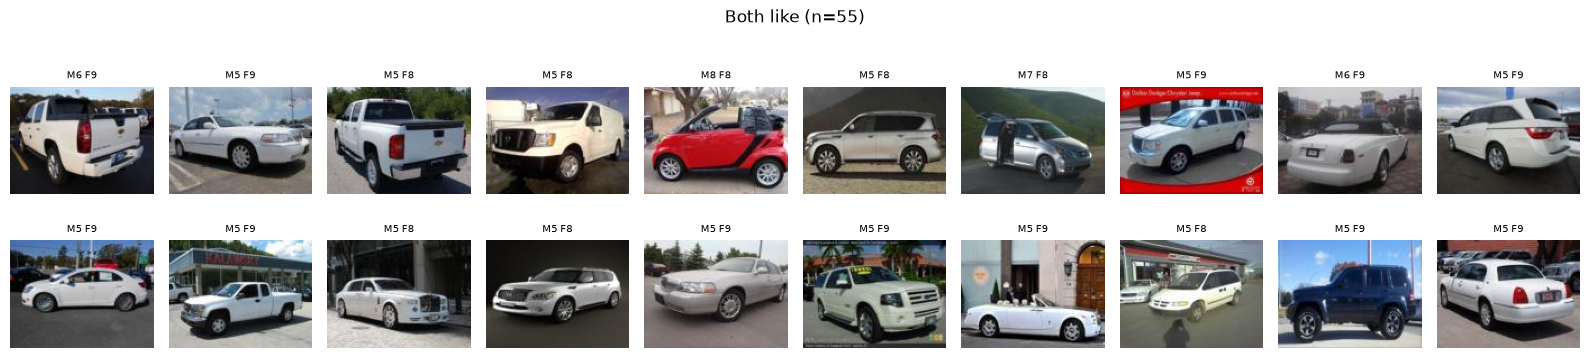

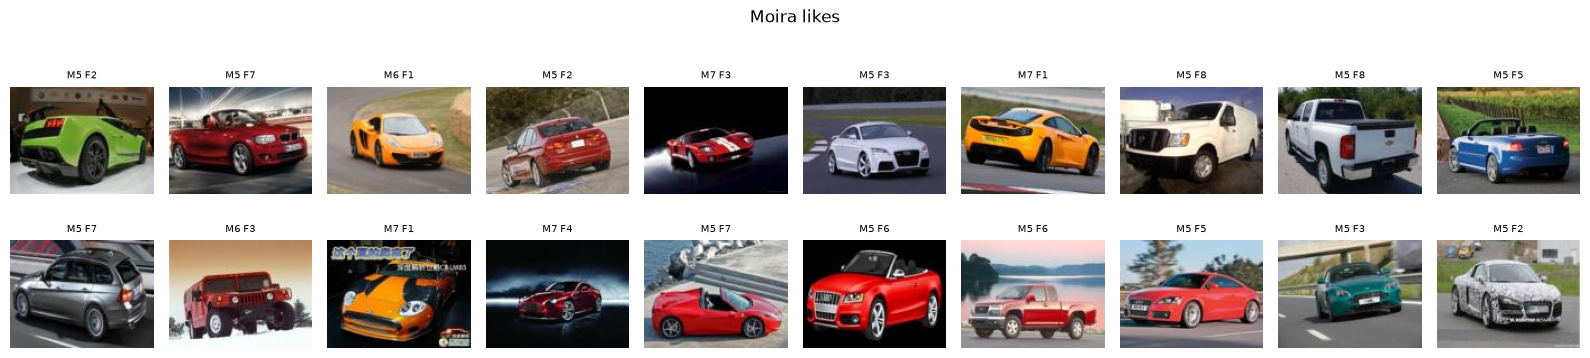

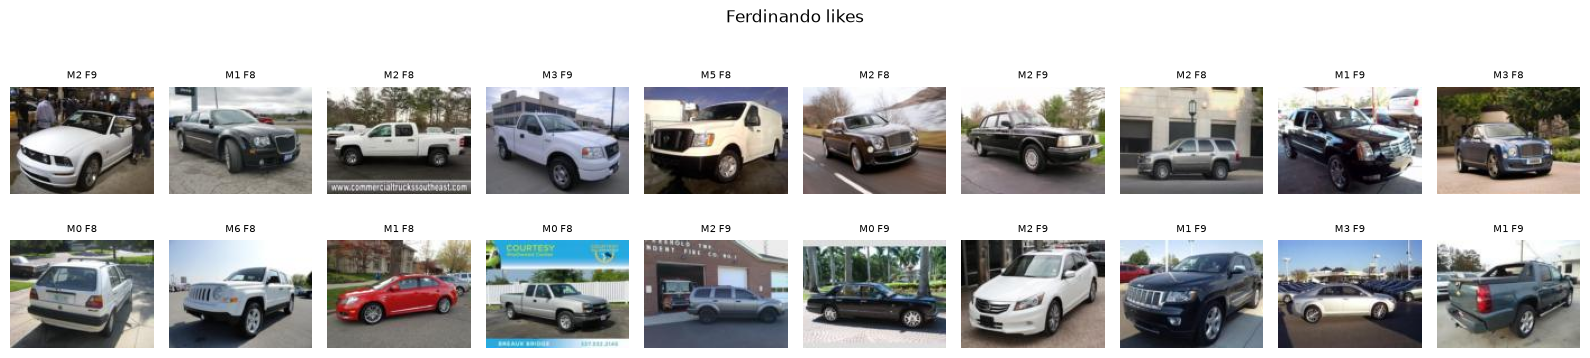

In [7]:
show(data, shared_liked_cars, f"Both like (n={len(shared_liked_cars)})")
show(data, moira_top, "Moira likes")
show(data, ferdinando_top, "Ferdinando likes")
plt.show()

## 2. Score regressor

ResNet-18 to six outputs, targets divided by 9. The split is fixed across
seeds so the ensemble members share a held-out set. Seeds 1 and 2 are trained
by `make regressor`.

In [8]:
train_idx, test_idx = split_indices(len(data))
train_loader, test_loader = make_loaders(data, train_idx, test_idx)

scores_all = torch.tensor(ratings.values, dtype=torch.float32)
base = constant_baseline(scores_all[train_idx], scores_all[test_idx])
print('constant baseline', base)

constant baseline 0.05701378360390663


Frozen backbone first, as a baseline. ImageNet features separate categories and
every image here is a car, so a linear probe has little to work with.

In [9]:
probe = make_regressor(freeze_backbone=True)
print(sum(p.requires_grad for p in probe.parameters()), 'trainable tensors')

# Load if trained before, otherwise train
if os.path.exists('output/probe.pth'):
    probe.load_state_dict(torch.load('output/probe.pth', map_location=device))
else:
    train_regressor(probe, train_loader, test_loader, epochs=30, ckpt='output/probe.pth')

2 trainable tensors


Probe training log:

```
2 trainable tensors
  0 val 0.37039
  1 val 0.29853
  2 val 0.23822
  3 val 0.19970
  4 val 0.17243
  5 val 0.14960
  6 val 0.13575
  7 val 0.12300
  8 val 0.11157
  9 val 0.10290
 10 val 0.09614
 11 val 0.09018
 12 val 0.08568
 13 val 0.08125
 14 val 0.07678
 15 val 0.07391
 16 val 0.07186
 17 val 0.06825
 18 val 0.06755
 19 val 0.06542
 20 val 0.06317
 21 val 0.06258
 22 val 0.06038
 23 val 0.05909
 24 val 0.05888
 25 val 0.05798
 26 val 0.05619
 27 val 0.05527
 28 val 0.05439
 29 val 0.05367
```

In [10]:
P, T = predict(probe, test_loader)
evaluate(P, T)

Raouf n=600 r2=0.130 rho=0.414 mae=1.70
Moira n=600 r2=0.092 rho=0.388 mae=1.27
Louie n=600 r2=-0.226 rho=0.306 mae=1.56
Ferdinando n=600 r2=-0.028 rho=0.465 mae=1.77
Gragar n=600 r2=0.068 rho=0.404 mae=1.80
Esther n=600 r2=0.174 rho=0.489 mae=1.88
pred corr M/F: -0.24700807502243058


,rater,n,r2,rho,mae
0,Raouf,600,0.130355,0.414384,1.697603
1,Moira,600,0.092042,0.387764,1.268898
2,Louie,600,-0.225520,0.306463,1.564561
3,Ferdinando,600,-0.027590,0.464550,1.766492
4,Gragar,600,0.067867,0.403754,1.803443
5,Esther,600,0.174212,0.489006,1.877557


Full fine-tuning. Reaches the probe's final loss in one epoch and settles
around 0.036.

In [11]:
torch.manual_seed(SEED)
regressor_res18 = make_regressor()

# Load if trained before, otherwise train
if os.path.exists('output/reg_seed0.pth'):
    regressor_res18.load_state_dict(torch.load('output/reg_seed0.pth', map_location=device))
else:
    train_regressor(regressor_res18, train_loader, test_loader, epochs=30, ckpt='output/reg_seed0.pth')

In [12]:
P, T = predict(regressor_res18, test_loader)
res = evaluate(P, T)

Raouf n=600 r2=0.448 rho=0.642 mae=1.34
Moira n=600 r2=0.288 rho=0.517 mae=1.11
Louie n=600 r2=0.285 rho=0.546 mae=1.19
Ferdinando n=600 r2=0.408 rho=0.652 mae=1.32
Gragar n=600 r2=0.311 rho=0.550 mae=1.54
Esther n=600 r2=0.461 rho=0.690 mae=1.52
pred corr M/F: -0.3312182533840371


The predicted M/F correlation lands near the -0.27 measured on the labels, so
the model kept the two tastes apart instead of collapsing onto a single
attractiveness direction.

Tail performance next, since the optimiser will only ever visit the top of the
range.

Only 12 held-out cars have Moira at 7 or above, so her tail numbers below are
noisy and should not be over-read.

In [13]:
evaluate(P, T, mask=lambda t: t >= 7)

Raouf n=78 r2=-8.396 rho=0.447 mae=2.12
Moira n=12 r2=-21.785 rho=0.055 mae=3.19
Louie n=32 r2=-40.661 rho=0.217 mae=2.84
Ferdinando n=258 r2=-4.209 rho=0.350 mae=1.39
Gragar n=163 r2=-13.740 rho=0.094 mae=1.94
Esther n=209 r2=-5.330 rho=0.246 mae=1.38
pred corr M/F: -0.3312182533840371


,rater,n,r2,rho,mae
0,Raouf,78,-8.395629,0.446527,2.121215
1,Moira,12,-21.785152,0.055240,3.187494
2,Louie,32,-40.660660,0.217343,2.844763
3,Ferdinando,258,-4.209419,0.349984,1.393564
4,Gragar,163,-13.739790,0.094492,1.937178
5,Esther,209,-5.330157,0.246269,1.375235


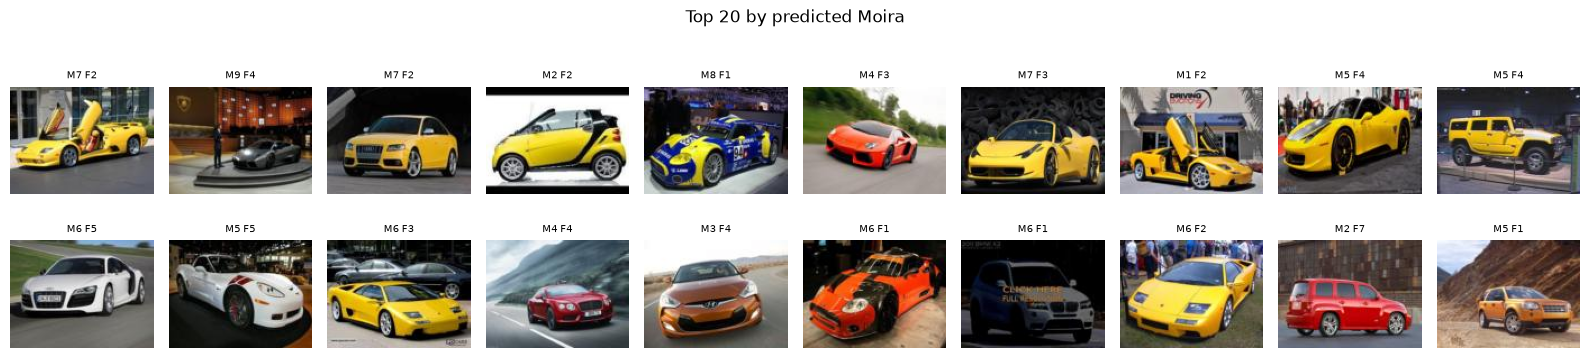

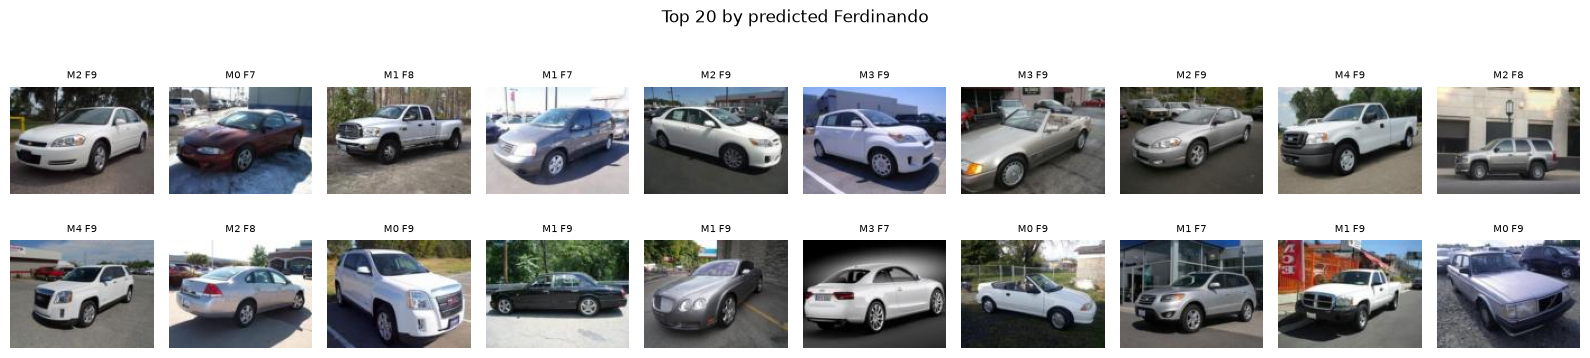

In [14]:
order = P[:, MOIRA].argsort()[::-1][:20]
show(data, [test_idx[i] for i in order], "Top 20 by predicted Moira")

order = P[:, FERDINANDO].argsort()[::-1][:20]
show(data, [test_idx[i] for i in order], "Top 20 by predicted Ferdinando")
plt.show()

## 3. Latent space

Frozen SD VAE (`stabilityai/sd-vae-ft-mse`). All 6000 cars are encoded once by
`src/encode_latents.py` (`make latents`) into `output/latents.pth`. Here we
only load the cache and check the reconstructions.

In [15]:
from diffusers import AutoencoderKL
vae = AutoencoderKL.from_pretrained(VAE_NAME).to(device).eval()

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


In [16]:
latent_dict = torch.load('output/latents.pth', map_location=device, weights_only=False)
latents_train = latent_dict['latents_train']
latents_test = latent_dict['latents_test']
scores_train = latent_dict['scores_train']
scores_test = latent_dict['scores_test']
train_idx = latent_dict['train_idx']
test_idx = latent_dict['test_idx']
scaling_factor = latent_dict['scaling_factor']


In [17]:
latents_train.shape

torch.Size([5400, 4, 12, 16])

In [18]:
latents_train.mean(), latents_train.std()

(tensor(0.0120, device='cuda:0'), tensor(0.8214, device='cuda:0'))

Reconstruction check: encode, decode straight back, compare with the originals.

In [19]:
with torch.no_grad():
    z = latents_test[:8] / vae.config.scaling_factor
    rec = vae.decode(z.to(device)).sample
    rec = ((rec + 1) / 2).clamp(0, 1)

In [20]:
orig = torch.stack([data[int(i)][0] for i in test_idx[:8]])
orig01 = denorm(orig).to(device)
mse = ((rec - orig01)**2).mean()
mse

tensor(0.0047, device='cuda:0')

In [21]:
with torch.no_grad():
    order = (-P[:, MOIRA]).argsort()[:5]
    z = latents_test[order] / vae.config.scaling_factor
    rec = vae.decode(z.to(device)).sample
    rec = ((rec + 1) / 2).clamp(0, 1)

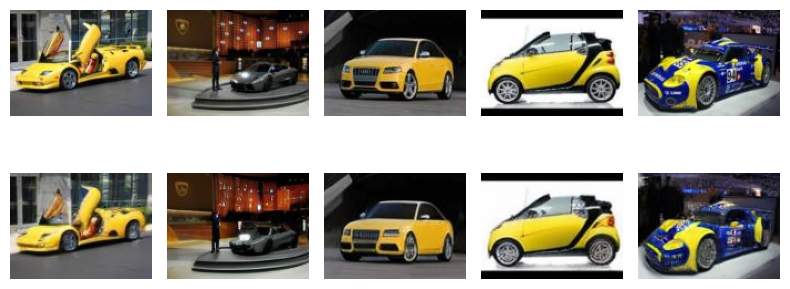

In [22]:
orig = torch.stack([data[int(test_idx[i])][0] for i in order])
orig01 = denorm(orig)

n = len(order)
fig, axes = plt.subplots(2, n, figsize=(n * 1.6, 4))
for k in range(n):
    axes[0, k].imshow(orig01[k].permute(1, 2, 0).numpy())
    axes[1, k].imshow(rec[k].cpu().permute(1, 2, 0).numpy())
    axes[0, k].axis('off')
    axes[1, k].axis('off')
axes[0, 0].set_ylabel('original')
plt.tight_layout()
plt.show()

Colour and body shape survive, fine detail (badges, spokes) softens. The
decoder is not the bottleneck for what Moira responds to.

## 4. Flow matching network

The classes live in `src/model_fm.py`. Each block is checked on its own before
assembling the U-Net.

In [23]:
emb = SinusoidalEmbedding(256)
t = torch.tensor([0.0, 0.3, 0.35, 1.0])
e = emb(t)
print(e.shape)
print(torch.cdist(e, e))

torch.Size([4, 256])
tensor([[ 0.0000, 13.0962, 13.3647, 14.3776],
        [13.0962,  0.0000, 11.1686, 14.3968],
        [13.3647, 11.1686,  0.0000, 14.2417],
        [14.3776, 14.3968, 14.2417,  0.0000]])


In [24]:
TimeMLP(256)(torch.rand(8)).shape

torch.Size([8, 256])

In [25]:
ce = ConEmbedding(256)
c = torch.rand(8, 6)
drop = torch.tensor([True, False] * 4)
out = ce(c, drop)
out.sum().backward()
print(out.shape, ce.null_embd.grad.abs().sum())

torch.Size([8, 256]) tensor(1024.)


In [26]:
x = torch.randn(8, 128, 3, 4)
e1 = torch.randn(8, 256)
e2 = torch.randn(8, 256)
res = ResBlock(128, 256, 256)

print(torch.allclose(res(x, e1), res(x, e2)))

nn.init.normal_(res.embd_proj[1].weight)
print(torch.allclose(res(x, e1), res(x, e2)))

True
False


In [27]:
attn_block = AttenBlock(8, 384)
x = torch.randn(8, 384, 3, 4)

attn_block(x).shape

torch.Size([8, 384, 3, 4])

Full U-Net: output has the input's shape, about 33M parameters, and the
zero-initialised head makes the first prediction exactly zero.

In [28]:
x = torch.randn(8, 4, 12, 16)
t = torch.rand(8)
c = torch.rand(8, 6)
drop = torch.zeros(8, dtype=torch.bool)

unet = UNet()
result = unet(x, t, c, drop)
result.shape

torch.Size([8, 4, 12, 16])

In [29]:
sum(p.numel() for p in unet.parameters())


32809476

In [30]:
result.abs().max()

tensor(0., grad_fn=<MaxBackward1>)

Overfit test: 16 latents with noise and times fixed, so the network sees the
same problem every step. It should start near 1 + 0.82^2 = 1.67 (zero
prediction against unit noise plus the latent variance) and fall towards zero.

In [31]:
size = 16
rng = np.random.default_rng(SEED)
idx = rng.permutation(size)
drop_n = round(size*0.1)
idx = idx[:drop_n]

drop = torch.zeros(size, dtype=torch.bool, device=device)
drop[idx] = 1

unet = UNet().to(device)
unet.train()
t = torch.rand(16, device=device)

x1 = latents_train[:16]
c = (scores_train[:16]/9.0).to(device)

x0 = torch.randn_like(x1)

t_ = t[:, None, None, None]

xt = (1-t_) * x0 + (t_) * x1
target = x1 - x0

opt = torch.optim.AdamW(unet.parameters(), lr=1e-4)

for step in range(1000):
    pred = unet(xt, t, c, drop)
    loss = nn.functional.mse_loss(pred, target)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 100 == 0:
        print(step, loss.item())

0 1.6324224472045898
100 0.31246358156204224


200 0.005936573725193739
300 0.002373666036874056
400 3.025775367859751e-05
500 5.821298327646218e-05
600 8.039076419663616e-06
700 1.5086384337337222e-05
800 1.7006852431222796e-05
900 0.00022150743461679667


## 5. Training

Full training on all 5400 latents: fresh noise every step, 10% condition
dropout, gradient clipping and an EMA copy. The cell below runs it here. It
skips if `output/fm_ema.pth` already exists, and resumes from
`output/fm_ckpt.pth` if a previous run was cut off, so rerunning is safe.

It takes about an hour on one GPU and is tied to this kernel. For a run that
survives a lost connection, use `sbatch run.slurm` instead and come back to
the plot below.

In [32]:
import train_fm

train_fm.main()

32 ms/step, about 21 min left at most
step 200 train 1.2382 val_ema 1.5952
step 400 train 1.0302 val_ema 1.4752
step 600 train 1.0027 val_ema 1.3684
step 800 train 0.9885 val_ema 1.2789
step 1000 train 0.9749 val_ema 1.2044
step 1200 train 0.9622 val_ema 1.1431
step 1400 train 0.9545 val_ema 1.0936
step 1600 train 0.9451 val_ema 1.0540
step 1800 train 0.9363 val_ema 1.0232
step 2000 train 0.9327 val_ema 0.9990
step 2200 train 0.9265 val_ema 0.9801
step 2400 train 0.9215 val_ema 0.9657
step 2600 train 0.9140 val_ema 0.9544
step 2800 train 0.9094 val_ema 0.9458
step 3000 train 0.9047 val_ema 0.9392
step 3200 train 0.9007 val_ema 0.9340
step 3400 train 0.8931 val_ema 0.9301
step 3600 train 0.8898 val_ema 0.9272
step 3800 train 0.8852 val_ema 0.9252
step 4000 train 0.8790 val_ema 0.9238
step 4200 train 0.8732 val_ema 0.9229
step 4400 train 0.8684 val_ema 0.9227
step 4600 train 0.8626 val_ema 0.9232
step 4800 train 0.8582 val_ema 0.9241
step 5000 train 0.8522 val_ema 0.9255
step 5200 train 

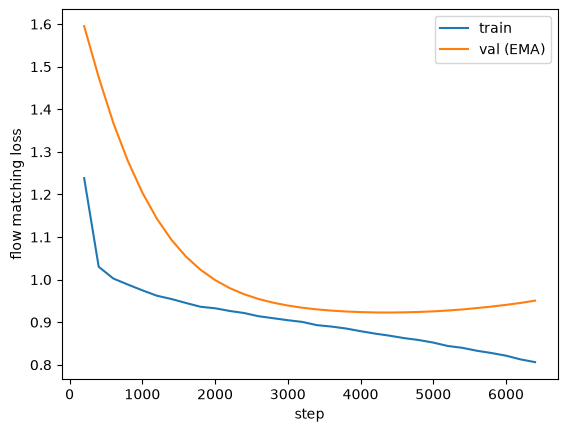

In [33]:
if os.path.exists('output/fm_log.csv'):
    log = pd.read_csv('output/fm_log.csv')
    plt.plot(log['step'], log['train'], label='train')
    plt.plot(log['step'], log['val_ema'], label='val (EMA)')
    plt.xlabel('step')
    plt.ylabel('flow matching loss')
    plt.legend()
    plt.show()

## 6. Cars for Moira

Draws 512 candidates at Moira = 9, scores them with the regressor ensemble,
drops near-copies of real cars and keeps 10 good, distinct ones. It writes
`images.pth`, `embeddings.pth` and `final_model.pth`, and skips if all three
already exist. The cells after it show the result.

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


samples: 1 regressor(s) in the ensemble
round trip ok, max abs diff 0.00e+00
wrote 10 images, embedding dim 774
samples: predicted Moira of the final 10: [8.15, 7.61, 7.47, 7.32, 7.26, 7.23, 7.17, 7.1, 7.07, 6.99]
  n_candidates: 512
  guidance: 2.0
  euler_steps: 50
  pred_moira_all_candidates: 5.005098342895508
  pred_moira_selected: 7.336487770080566
  pred_moira_control_cond0: 1.7548415660858154
  pred_moira_control_cond9: 5.069220066070557
  real_moira_mean_train: 2.0092592239379883
  novel_fraction: 0.79296875
  copy_threshold: 22.86443328857422


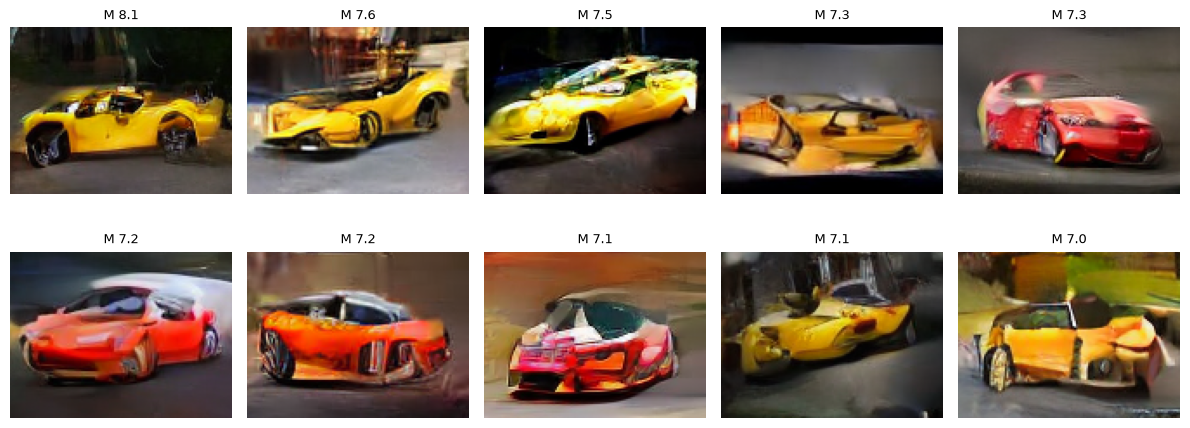

In [34]:
import select_images

select_images.main()

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


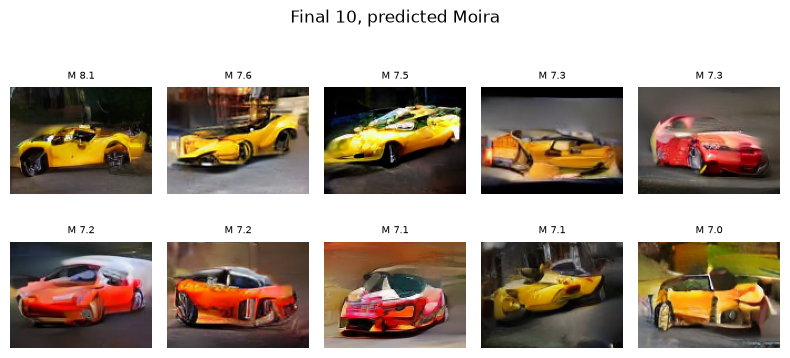

In [35]:
from generator import CarGenerator
from regressor import load_ensemble, ensemble_scores

if os.path.exists('output/final_model.pth'):
    gen = CarGenerator.from_checkpoint('output/final_model.pth')
    images = torch.load('output/images.pth', map_location=device)
    emb = torch.load('output/embeddings.pth', map_location=device)

    paths = [f'output/reg_seed{s}.pth' for s in range(3)]
    ens = load_ensemble([p for p in paths if os.path.exists(p)])
    with torch.no_grad():
        pred = ensemble_scores(ens, images)

    captions = [f'M {p:.1f}' for p in pred[:, MOIRA].tolist()]
    show_tensor(images, 'Final 10, predicted Moira', captions=captions)
    plt.show()

Conditioning check: the same noise decoded at Moira = 0 and Moira = 9. If the
two rows look alike, the model ignores the scores.

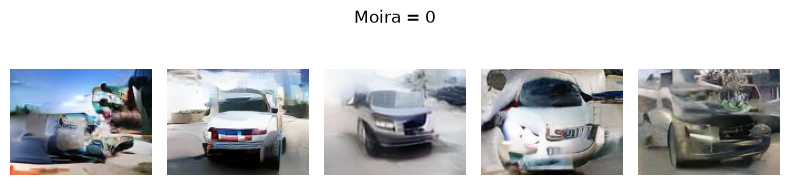

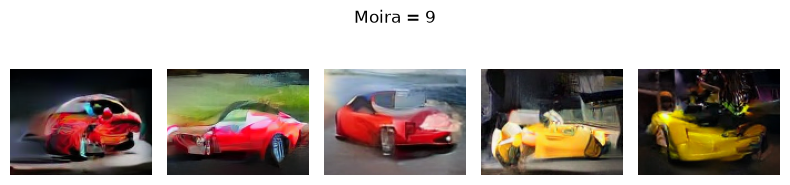

In [36]:
if os.path.exists('output/final_model.pth'):
    g = torch.Generator(device=device).manual_seed(SEED)
    z = torch.randn(5, LATENT_DIM, device=device, generator=g)
    c = emb[0, LATENT_DIM:].repeat(5, 1)

    c0 = c.clone()
    c0[:, MOIRA] = 0
    c9 = c.clone()
    c9[:, MOIRA] = 9

    show_tensor(gen.decode(z, c0), 'Moira = 0')
    show_tensor(gen.decode(z, c9), 'Moira = 9')
    plt.show()

In [37]:
import json

if os.path.exists('output/selection_stats.json'):
    stats = json.load(open('output/selection_stats.json'))
    for k, v in stats.items():
        print(k, v)

n_candidates 512
guidance 2.0
euler_steps 50
target_scores [3.6770293712615967, 9.0, 2.6839377880096436, 3.9827287197113037, 5.6597580909729, 6.449049949645996]
pred_moira_all_candidates 5.005098342895508
pred_moira_selected 7.336487770080566
pred_moira_control_cond0 1.7548415660858154
pred_moira_control_cond9 5.069220066070557
real_moira_mean_train 2.0092592239379883
novel_fraction 0.79296875
copy_threshold 22.86443328857422
selected_nn_dist [24.693614959716797, 26.60075569152832, 26.19061851501465, 23.49331283569336, 23.4497127532959, 23.76755714416504, 24.87432289123535, 23.812997817993164, 24.926912307739258, 25.378572463989258]
